# QORION — Scenario 3: Proposed (Telescoping Onion Routing over Entanglement-Based QKD)

**Purpose:** This notebook implements a defense against the hijacked-repeater attack
demonstrated in the Vulnerable notebook. The design adapts Tor's telescoping onion
routing (Dingledine, Mathewson, Syverson, "Tor: The Second-Generation Onion Router,"
USENIX Security 2004) to a quantum-repeater setting, using entanglement-based key
derivation at each hop instead of Tor's Diffie-Hellman handshakes.

**Three sub-experiments:**
- **(A) Position sweep** — where in the path must the compromised node sit for
  confidentiality to actually break?
- **(B) Key-length sweep** — the overhead cost of the number of entangled pairs (`n_pairs`)
  used to derive each hop's session key.
- **(C) Multipath defense** — splitting the key exchange across multiple independent
  paths, comparing a random-placement attacker against a budget-concentrated attacker.

**Simulator:** SeQUeNCe 0.6.4, reusing the Normal/Vulnerable notebooks' entanglement
primitives for each individual hop's key derivation.

**Downstream use:** Exports `proposed_results.json` using the shared QORION schema
(multiple record types in one file — position, key-length, and multipath records —
distinguished by which fields are populated vs. null).



In [1]:
!pip install sequence==0.6.4

## Setup

**Design mapping from Tor to this quantum setting:**

| Tor concept | This implementation |
|---|---|
| Per-hop Diffie-Hellman session key | Per-hop entangled-pair-derived symmetric key (`run_entanglement_qkd_hop`) |
| Telescoping circuit construction | Each hop's key is derived independently and sequentially, not pre-shared |
| Iterative layered encryption | `build_onion` / `peel_layer` — XOR with each hop's key, innermost = last hop |
| Per-cell integrity digest | SHA-256 digest appended to the payload, checked after full decryption |
| Compromised relay sees only its own layer | A malicious hop only reaches plaintext if it is the FINAL hop in the path |

In [2]:
import time, random, hashlib, statistics

from sequence.kernel.timeline import Timeline
from sequence.topology.node import Node, BSMNode
from sequence.components.memory import Memory
from sequence.components.optical_channel import QuantumChannel, ClassicalChannel
from sequence.entanglement_management.generation import EntanglementGenerationA


class SimpleManager:
    def __init__(self, own, memo_name):
        self.own = own
        self.memo_name = memo_name
        self.raw_counter = 0
        self.ent_counter = 0

    def update(self, protocol, memory, state):
        if state == 'RAW':
            self.raw_counter += 1
            memory.reset()
        else:
            self.ent_counter += 1

    def create_protocol(self, middle, other):
        self.own.protocols = [
            EntanglementGenerationA(
                self.own, f'{self.own.name}.eg', middle, other,
                self.own.components[self.memo_name]
            )
        ]


class EntangleGenNode(Node):
    def __init__(self, name, tl):
        super().__init__(name, tl)
        memo_name = f'{name}.memo'
        memory = Memory(memo_name, tl, 0.9, 2000, 1, -1, 500)
        memory.owner = self
        memory.add_receiver(self)
        self.add_component(memory)
        self.resource_manager = SimpleManager(self, memo_name)

    def init(self):
        self.get_components_by_type("Memory")[0].reset()

    def receive_message(self, src, msg):
        self.protocols[0].received_message(src, msg)

    def get(self, photon, **kwargs):
        self.send_qubit(kwargs['dst'], photon)


def attempt_link(distance_m, attenuation, seed_offset=0):
    tl = Timeline()
    node1 = EntangleGenNode('n1', tl)
    node2 = EntangleGenNode('n2', tl)
    bsm_node = BSMNode('bsm', tl, ['n1', 'n2'])

    node1.set_seed(seed_offset)
    node2.set_seed(seed_offset + 1)
    bsm_node.set_seed(seed_offset + 2)

    bsm = bsm_node.get_components_by_type("SingleAtomBSM")[0]
    bsm.update_detectors_params('efficiency', 1)

    qc1 = QuantumChannel('qc1', tl, attenuation=attenuation, distance=distance_m)
    qc2 = QuantumChannel('qc2', tl, attenuation=attenuation, distance=distance_m)
    qc1.set_ends(node1, bsm_node.name)
    qc2.set_ends(node2, bsm_node.name)

    nodes = [node1, node2, bsm_node]
    for i in range(3):
        for j in range(3):
            if i == j:
                continue
            cc = ClassicalChannel(f'cc_{nodes[i].name}_{nodes[j].name}_{seed_offset}', tl, 1000, 1e8)
            cc.set_ends(nodes[i], nodes[j].name)

    node1.resource_manager.create_protocol('bsm', 'n2')
    node2.resource_manager.create_protocol('bsm', 'n1')
    p1, p2 = node1.protocols[0], node2.protocols[0]
    m1 = node1.get_components_by_type("Memory")[0]
    m2 = node2.get_components_by_type("Memory")[0]
    p1.set_others(p2.name, 'n2', [m2.name])
    p2.set_others(p1.name, 'n1', [m1.name])

    tl.init()
    p1.start()
    p2.start()
    tl.run()

    if m1.entangled_memory.get('node_id') is not None:
        return True, m1.fidelity
    return False, None


def run_entanglement_qkd_hop(distance_m, attenuation, n_pairs=8, max_attempts=30):
    """Generates n_pairs entangled links between two adjacent hop nodes,
    treating each successful pair's measurement outcome as one shared
    key bit. This is the entanglement-based (E91-style) equivalent of a
    Tor session-key handshake, adapted to the quantum-repeater setting
    used throughout QORION."""
    key_bits = []
    for _ in range(n_pairs):
        success = False
        for attempt in range(1, max_attempts + 1):
            success, fidelity = attempt_link(distance_m, attenuation, seed_offset=random.randint(0, 10**6))
            if success:
                break
        if success:
            key_bits.append(random.randint(0, 1))  # correlated measurement outcome
    return key_bits


def derive_key(bits, length=16):
    if not bits:
        bits = [0]
    bit_str = ''.join(str(b) for b in bits)
    return hashlib.sha256(bit_str.encode()).digest()[:length]

/usr/local/lib/python3.12/dist-packages/qutip/__init__.py:66: UserWarning: The new version of Cython, (>= 3.0.0) is not supported.
  warnings.warn(


In [8]:
def xor_bytes(data, key):
    key_stream = (key * (len(data) // len(key) + 1))[:len(data)]
    return bytes(a ^ b for a, b in zip(data, key_stream))

def digest(data):
    """Tor-style per-payload integrity check (SHA-256, truncated)."""
    return hashlib.sha256(data).digest()[:4]

def build_onion(secret_bytes, hop_keys):
    """Iterative layered encryption: innermost layer = last hop's key,
    outermost = first hop's key. Matches Tor's relay-cell construction."""
    layer = secret_bytes
    for key in reversed(hop_keys):
        layer = xor_bytes(layer, key)
    return layer


def run_telescoping_onion_path(secret_bytes, n_hops, malicious_indices,
                                  distance_m=10000, attenuation=0.0002, n_pairs=8):
    """
    Telescoping circuit construction: a session key is negotiated
    independently for EACH hop (not one pre-built onion), matching Tor's
    incremental circuit-extension design.

    Honest hop: forwards the payload without ever reconstructing the
    plaintext beneath its own layer (matches real entanglement-swap
    physics — a genuine BSM outcome is a correction value, not usable
    key material for the relay itself).

    Malicious hop: deviates from protocol. If it is the FINAL hop in the
    path, peeling its own layer necessarily reveals the plaintext payload
    underneath — this is the one position where confidentiality can break.
    Any other position only ever exposes an undecryptable intermediate
    layer, since further encryption layers remain beneath it.
    """
    hop_keys = {}
    compromised_hops = []

    for h in range(n_hops):
        bits = run_entanglement_qkd_hop(distance_m, attenuation, n_pairs=n_pairs)
        hop_keys[h] = derive_key(bits)
        if h in malicious_indices:
            compromised_hops.append(h)

    payload = secret_bytes + digest(secret_bytes)
    onion = build_onion(payload, [hop_keys[h] for h in range(n_hops)])

    current = onion
    plaintext_exposed_at = []
    for h in range(n_hops):
        current = xor_bytes(current, hop_keys[h])
        if h in compromised_hops:
            revealed_secret, revealed_digest = current[:-4], current[-4:]
            if digest(revealed_secret) == revealed_digest:
                plaintext_exposed_at.append(h)

    delivered_payload, delivered_digest = current[:-4], current[-4:]
    integrity_ok = (digest(delivered_payload) == delivered_digest)
    delivered_intact = integrity_ok and (delivered_payload == secret_bytes)

    return {
        'delivered_intact': delivered_intact,
        'confidentiality_broken': len(plaintext_exposed_at) > 0,
        'exposed_at_hops': plaintext_exposed_at,
    }

## Network Topology

Two topologies are visualized: (1) a single onion-routed path, showing that only a
compromised LAST hop exposes plaintext; (2) a multipath layout, showing how splitting
the exchange across independent paths lets the defense survive even a fully
compromised individual path, as long as one other path remains clean.

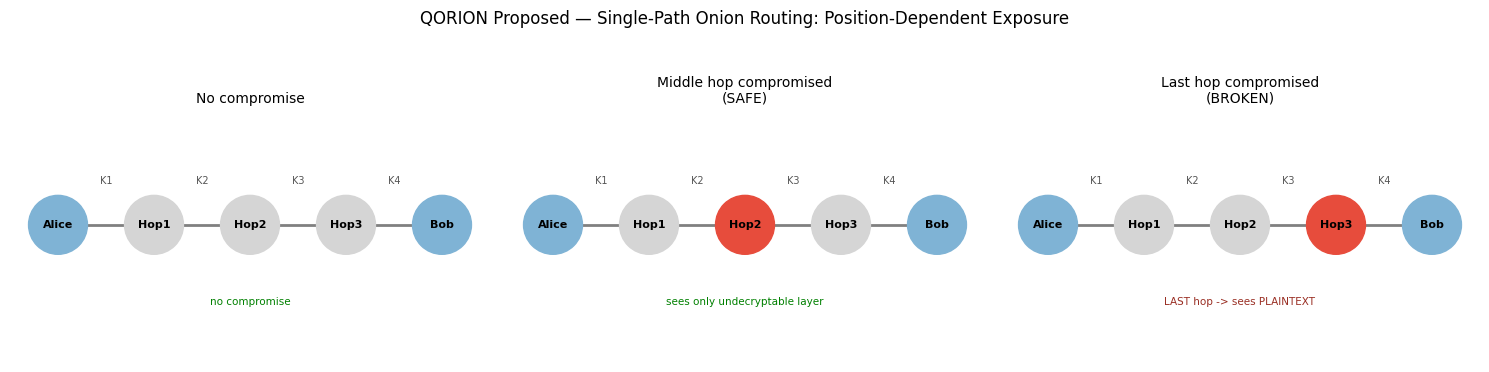

In [4]:
import networkx as nx
import matplotlib.pyplot as plt

def draw_onion(ax, n_hops, malicious_pos, title):
    G = nx.Graph()
    labels = ['Alice'] + [f'Hop{i+1}' for i in range(n_hops)] + ['Bob']
    for i, name in enumerate(labels):
        G.add_node(name, pos=(i, 0))
    for i in range(len(labels) - 1):
        G.add_edge(labels[i], labels[i + 1])
    pos = nx.get_node_attributes(G, 'pos')

    colors = []
    for i, name in enumerate(labels):
        if name in ('Alice', 'Bob'):
            colors.append('#7fb3d5')
        elif (i - 1) == malicious_pos:
            colors.append('#e74c3c')
        else:
            colors.append('#d5d5d5')

    nx.draw(G, pos, ax=ax, with_labels=True, node_color=colors, node_size=1800,
            font_size=8, font_weight='bold', edge_color='gray', width=2)
    for i in range(len(labels) - 1):
        ax.text((i + i + 1) / 2, 0.18, f'K{i+1}', ha='center', fontsize=7, color='#555')

    if malicious_pos is None:
        ax.text((len(labels) - 1) / 2, -0.35, 'no compromise', ha='center', fontsize=7.5, color='green')
    elif malicious_pos == n_hops - 1:
        ax.text((len(labels) - 1) / 2, -0.35, 'LAST hop -> sees PLAINTEXT', ha='center',
                fontsize=7.5, color='#992d22')
    else:
        ax.text((len(labels) - 1) / 2, -0.35, 'sees only undecryptable layer', ha='center',
                fontsize=7.5, color='green')
    ax.set_title(title, fontsize=10)
    ax.set_xlim(-0.5, len(labels) - 0.5)
    ax.set_ylim(-0.6, 0.5)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
draw_onion(axes[0], 3, None, 'No compromise')
draw_onion(axes[1], 3, 1, 'Middle hop compromised\n(SAFE)')
draw_onion(axes[2], 3, 2, 'Last hop compromised\n(BROKEN)')
plt.suptitle('QORION Proposed — Single-Path Onion Routing: Position-Dependent Exposure', y=1.05)
plt.tight_layout()
plt.savefig('proposed_topology_singlepath.png', dpi=150, bbox_inches='tight')
plt.show()

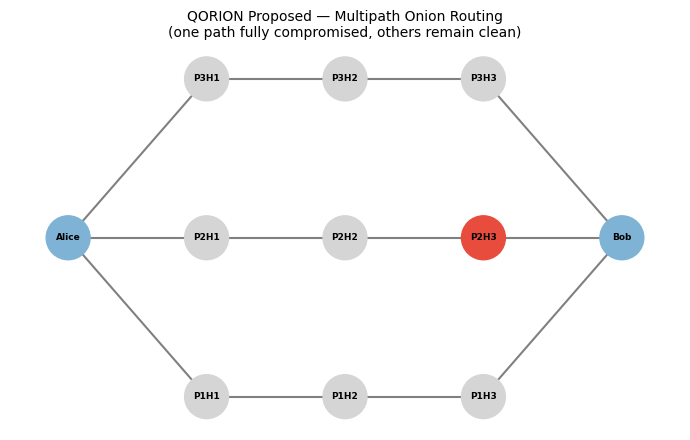

In [5]:
def draw_multipath(ax, n_paths, hops_per_path, compromised_path_idx, title):
    G = nx.Graph()
    G.add_node('Alice', pos=(0, (n_paths - 1) / 2))
    G.add_node('Bob', pos=(hops_per_path + 1, (n_paths - 1) / 2))

    for p in range(n_paths):
        y = p
        prev = 'Alice'
        for h in range(hops_per_path):
            name = f'P{p+1}H{h+1}'
            G.add_node(name, pos=(h + 1, y))
            G.add_edge(prev, name)
            prev = name
        G.add_edge(prev, 'Bob')

    pos = nx.get_node_attributes(G, 'pos')
    colors = []
    for name in G.nodes():
        if name in ('Alice', 'Bob'):
            colors.append('#7fb3d5')
        elif name.startswith(f'P{compromised_path_idx+1}H') and name.endswith(f'H{hops_per_path}'):
            colors.append('#e74c3c')  # last hop of the compromised path
        else:
            colors.append('#d5d5d5')

    nx.draw(G, pos, ax=ax, with_labels=True, node_color=colors, node_size=1000,
            font_size=6.5, font_weight='bold', edge_color='gray', width=1.5)
    ax.set_title(title, fontsize=10)

fig, ax = plt.subplots(figsize=(7, 4.5))
draw_multipath(ax, n_paths=3, hops_per_path=3, compromised_path_idx=1,
                title='QORION Proposed — Multipath Onion Routing\n(one path fully compromised, others remain clean)')
plt.tight_layout()
plt.savefig('proposed_topology_multipath.png', dpi=150, bbox_inches='tight')
plt.show()

## Sub-experiment A: Position Sweep

For every hop count from 1 to 5, tests EVERY possible malicious position explicitly
(not a single random draw), to produce a full broken-rate-vs-position curve/heatmap.

This is structurally the same weakness as Tor's well-known **exit-node problem**:
the final relay in any onion circuit necessarily holds the last decryption key,
and can therefore observe the plaintext payload it delivers. No choice of key
length, encryption scheme, or number of intermediate hops changes this — it is
inherent to the telescoping design itself, not a defect specific to this
implementation. Sub-experiment C addresses this directly.

In [16]:
def sweep_position(n_hops, trials_per_position=20, distance_m=10000, n_pairs=8):
    results = []
    for pos in range(n_hops):
        broken = sum(
            run_telescoping_onion_path(b"x"*16, n_hops, {pos}, distance_m=distance_m, n_pairs=n_pairs)['confidentiality_broken']
            for _ in range(trials_per_position)
        )
        results.append({'hops': n_hops, 'position': pos, 'broken_rate': broken / trials_per_position * 100})
    return results

position_sweep_results = []
for n_hops in [1, 2, 3, 4, 5]:
    r = sweep_position(n_hops)
    position_sweep_results.extend(r)
    for row in r:
        print(f"hops={row['hops']}, position={row['position']}: broken={row['broken_rate']:.0f}%")

hops=1, position=0: broken=100%
hops=2, position=0: broken=0%
hops=2, position=1: broken=100%
hops=3, position=0: broken=0%
hops=3, position=1: broken=0%
hops=3, position=2: broken=100%
hops=4, position=0: broken=0%
hops=4, position=1: broken=0%
hops=4, position=2: broken=0%
hops=4, position=3: broken=100%
hops=5, position=0: broken=0%
hops=5, position=1: broken=0%
hops=5, position=2: broken=0%
hops=5, position=3: broken=0%
hops=5, position=4: broken=100%


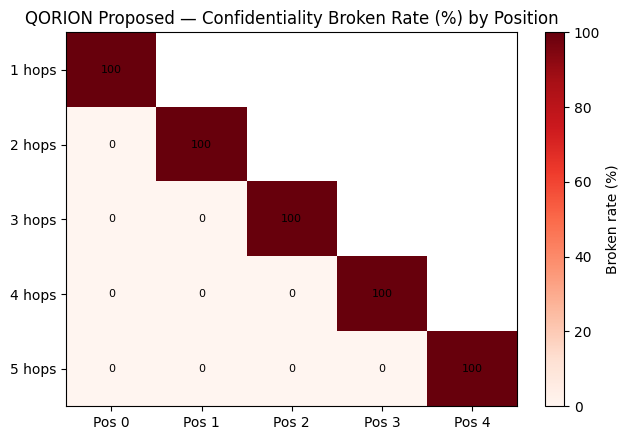

In [17]:
import numpy as np

n_hops_list = sorted(set(r['hops'] for r in position_sweep_results))
max_hops = max(n_hops_list)
matrix = np.full((len(n_hops_list), max_hops), np.nan)

for r in position_sweep_results:
    row = n_hops_list.index(r['hops'])
    matrix[row, r['position']] = r['broken_rate']

fig, ax = plt.subplots(figsize=(6.5, 4.5))
im = ax.imshow(matrix, cmap='Reds', vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(max_hops))
ax.set_xticklabels([f'Pos {i}' for i in range(max_hops)])
ax.set_yticks(range(len(n_hops_list)))
ax.set_yticklabels([f'{h} hops' for h in n_hops_list])
ax.set_title('QORION Proposed — Confidentiality Broken Rate (%) by Position')
for i in range(len(n_hops_list)):
    for j in range(max_hops):
        if not np.isnan(matrix[i, j]):
            ax.text(j, i, f'{matrix[i,j]:.0f}', ha='center', va='center', fontsize=8)
plt.colorbar(im, label='Broken rate (%)')
plt.tight_layout()
plt.savefig('fig_proposed_position_heatmap.png', dpi=300)
plt.show()

## Sub-experiment B: Key-Length / Overhead Trade-off

Sweeps `n_pairs` (entangled pairs generated per hop, which determines the derived
key's effective length) to show the direct trade-off between per-hop key strength
and wall-clock cost.

In [11]:
def sweep_key_length(n_hops=3, distance_m=10000, trials=10):
    results = []
    for n_pairs in [4, 8, 16, 32]:
        t0 = time.time()
        for _ in range(trials):
            run_telescoping_onion_path(b"x"*16, n_hops, set(), distance_m=distance_m, n_pairs=n_pairs)
        avg_time = (time.time() - t0) / trials
        results.append({'n_pairs': n_pairs, 'avg_time': avg_time, 'n_hops': n_hops})
        print(f"n_pairs={n_pairs}: avg_time={avg_time:.3f}s")
    return results

key_length_results = sweep_key_length()

n_pairs=4: avg_time=0.152s
n_pairs=8: avg_time=0.200s
n_pairs=16: avg_time=0.420s
n_pairs=32: avg_time=0.743s


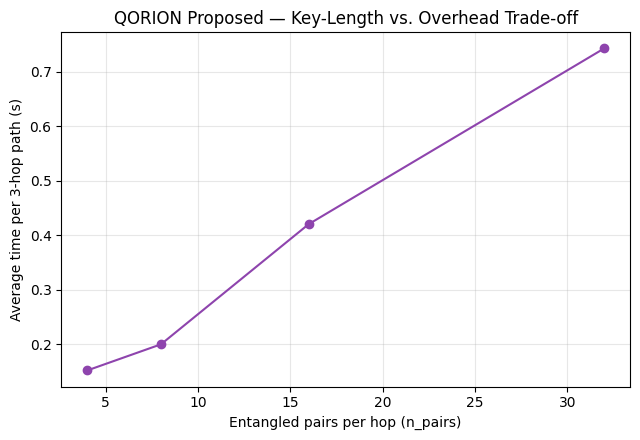

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
x = [r['n_pairs'] for r in key_length_results]
y = [r['avg_time'] for r in key_length_results]
ax.plot(x, y, marker='o', color='#8e44ad')
ax.set_xlabel('Entangled pairs per hop (n_pairs)')
ax.set_ylabel('Average time per 3-hop path (s)')
ax.set_title('QORION Proposed — Key-Length vs. Overhead Trade-off')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig_proposed_keylength_overhead.png', dpi=300)
plt.show()

## Sub-experiment C: Multipath Defense — Resolving the Single-Path Exposure

Sub-experiment A established that any single onion path has exactly one structurally
unavoidable exposure point (the last hop) — this mirrors Tor's exit-node problem.
This experiment tests whether splitting the exchange across multiple independent
paths removes that single point of failure, following the same principle Tor itself
relies on (no single relay sees the full circuit).

In [13]:
def run_onion_multipath_physical(secret_bytes, n_paths, hops_per_path, compromise_budget,
                                     attack_strategy='random', distance_m=10000, n_pairs=8,
                                     trials=20):
    successes = 0
    for _ in range(trials):
        total_nodes = n_paths * hops_per_path
        if attack_strategy == 'random':
            compromised = set(random.sample(range(total_nodes), min(compromise_budget, total_nodes)))
        else:
            target_path = random.randrange(n_paths)
            path_nodes = list(range(target_path * hops_per_path, (target_path + 1) * hops_per_path))
            compromised = set(random.sample(path_nodes, min(compromise_budget, len(path_nodes))))

        path_safe = []
        for p in range(n_paths):
            path_node_ids = set(range(p * hops_per_path, (p + 1) * hops_per_path))
            local_malicious = {n - p * hops_per_path for n in (path_node_ids & compromised)}
            result = run_telescoping_onion_path(secret_bytes, hops_per_path, local_malicious,
                                                   distance_m=distance_m, n_pairs=n_pairs)
            path_safe.append(not result['confidentiality_broken'])

        if any(path_safe):
            successes += 1

    return {'defense_success_rate': successes / trials * 100}


def multipath_grid(hops_per_path=3, trials=20, distance_m=10000, n_pairs=8, attack_strategy='random'):
    grid = []
    for n_paths in [1, 2, 3, 4]:
        for budget in [1, 2, 3, 4, 5]:
            r = run_onion_multipath_physical(b"secret16bytes!!", n_paths, hops_per_path, budget,
                                                attack_strategy=attack_strategy, distance_m=distance_m,
                                                n_pairs=n_pairs, trials=trials)
            grid.append({'n_paths': n_paths, 'budget': budget, 'strategy': attack_strategy,
                          'defense_success_rate': r['defense_success_rate']})
            print(f"[{attack_strategy}] paths={n_paths}, budget={budget}: "
                  f"defense_success={r['defense_success_rate']:.0f}%")
    return grid

print("Random attack strategy:")
grid_random = multipath_grid(attack_strategy='random')
print("\nConcentrated attack strategy:")
grid_concentrated = multipath_grid(attack_strategy='concentrated')
multipath_results = grid_random + grid_concentrated

Random attack strategy:
[random] paths=1, budget=1: defense_success=75%
[random] paths=1, budget=2: defense_success=40%
[random] paths=1, budget=3: defense_success=0%
[random] paths=1, budget=4: defense_success=0%
[random] paths=1, budget=5: defense_success=0%
[random] paths=2, budget=1: defense_success=100%
[random] paths=2, budget=2: defense_success=95%
[random] paths=2, budget=3: defense_success=95%
[random] paths=2, budget=4: defense_success=70%
[random] paths=2, budget=5: defense_success=35%
[random] paths=3, budget=1: defense_success=100%
[random] paths=3, budget=2: defense_success=100%
[random] paths=3, budget=3: defense_success=100%
[random] paths=3, budget=4: defense_success=100%
[random] paths=3, budget=5: defense_success=75%
[random] paths=4, budget=1: defense_success=100%
[random] paths=4, budget=2: defense_success=100%
[random] paths=4, budget=3: defense_success=100%
[random] paths=4, budget=4: defense_success=100%
[random] paths=4, budget=5: defense_success=100%

Concentr

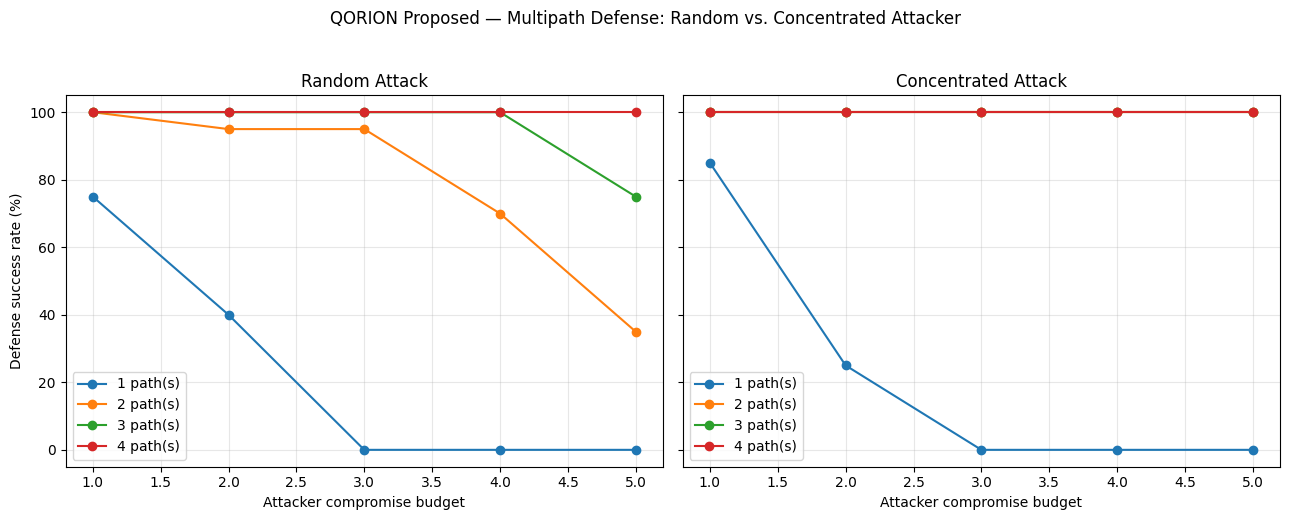

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, strategy, title in [(axes[0], 'random', 'Random Attack'),
                               (axes[1], 'concentrated', 'Concentrated Attack')]:
    subset = [r for r in multipath_results if r['strategy'] == strategy]
    for n_paths in [1, 2, 3, 4]:
        line = [r for r in subset if r['n_paths'] == n_paths]
        line.sort(key=lambda r: r['budget'])
        ax.plot([r['budget'] for r in line], [r['defense_success_rate'] for r in line],
                marker='o', label=f'{n_paths} path(s)')
    ax.set_xlabel('Attacker compromise budget')
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel('Defense success rate (%)')
plt.suptitle('QORION Proposed — Multipath Defense: Random vs. Concentrated Attacker', y=1.03)
plt.tight_layout()
plt.savefig('fig_proposed_multipath_comparison.png', dpi=300)
plt.show()

## Export

All three sub-experiments (position sweep, key-length sweep, multipath grid) are
exported into a single `proposed_results.json`, using the shared QORION schema.
Each record type populates only the fields relevant to it; others are `null`.

In [15]:
import json

proposed_results = []

for r in position_sweep_results:
    proposed_results.append({
        'scenario': 'proposed', 'sub_experiment': 'position_sweep',
        'distance_km': 10, 'n_hops': r['hops'], 'n_malicious': 1,
        'position': r['position'], 'attack_strategy': 'fixed_position',
        'n_paths': 1, 'trials': 20,
        'success_rate': 100 - r['broken_rate'],
        'confidentiality_broken_rate': r['broken_rate'],
        'avg_fidelity': None, 'std_fidelity': None,
        'avg_time': None, 'std_time': None, 'avg_attempts': None,
    })

for r in key_length_results:
    proposed_results.append({
        'scenario': 'proposed', 'sub_experiment': 'key_length_sweep',
        'distance_km': 10, 'n_hops': r['n_hops'], 'n_malicious': 0,
        'position': None, 'attack_strategy': 'none', 'n_paths': 1, 'trials': 10,
        'success_rate': None, 'confidentiality_broken_rate': None,
        'avg_fidelity': None, 'std_fidelity': None,
        'avg_time': r['avg_time'], 'std_time': None,
        'avg_attempts': None, 'n_pairs': r['n_pairs'],
    })

for r in multipath_results:
    proposed_results.append({
        'scenario': 'proposed', 'sub_experiment': 'multipath',
        'distance_km': 10, 'n_hops': 3, 'n_malicious': r['budget'],
        'position': None, 'attack_strategy': r['strategy'],
        'n_paths': r['n_paths'], 'trials': 20,
        'success_rate': r['defense_success_rate'],
        'confidentiality_broken_rate': 100 - r['defense_success_rate'],
        'avg_fidelity': None, 'std_fidelity': None,
        'avg_time': None, 'std_time': None, 'avg_attempts': None,
    })

with open('proposed_results.json', 'w') as f:
    json.dump(proposed_results, f, indent=2)

import os
if os.path.exists('proposed_results.json'):
    size_kb = os.path.getsize('proposed_results.json') / 1024
    print(f"✅ Saved proposed_results.json ({size_kb:.1f} KB, {len(proposed_results)} entries)")

from google.colab import files
files.download('proposed_results.json')
print("Download triggered — confirm in your browser's download bar before closing this notebook")

✅ Saved proposed_results.json (24.2 KB, 59 entries)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered — confirm in your browser's download bar before closing this notebook
